# Assignment 2

Colour image to grayscale.

Sample: `sample_blocks.png` (cream, lime and green blocks). Case 1 is the mean of R, G and B. Case 2 uses weights 0.7, 0.2 and 0.1, so the green blocks change.


In [1]:
%matplotlib inline
import cv2
import numpy as np
import matplotlib.pyplot as plt


# RGB to grayscale
# case 1: plain average of R, G, B
# case 2: weights from the user, each between 0 and 1, and they add up to 1

def gray_mean(img):
    # imread gives BGR, not RGB
    b, g, r = cv2.split(img)
    avg = (r.astype(np.float64) + g.astype(np.float64) + b.astype(np.float64)) / 3.0
    return np.clip(np.round(avg), 0, 255).astype(np.uint8)


def gray_weighted(img, wr, wg, wb):
    b, g, r = cv2.split(img)
    val = wr * r.astype(np.float64) + wg * g.astype(np.float64) + wb * b.astype(np.float64)
    return np.clip(np.round(val), 0, 255).astype(np.uint8)


sample image: sample_blocks.png (387, 384, 3)
weights R, G, B = 0.7 0.2 0.1
mean absolute difference between the two grays = 9.74


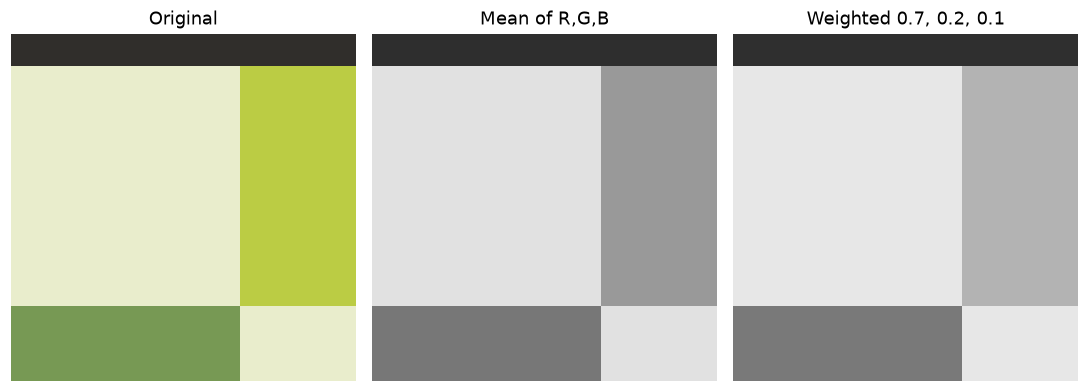

In [2]:
image_path = "sample_blocks.png"
wr, wg, wb = 0.7, 0.2, 0.1

img = cv2.imread(image_path)
print("sample image:", image_path, img.shape)
print("weights R, G, B =", wr, wg, wb)

mean_img = gray_mean(img)
w_img = gray_weighted(img, wr, wg, wb)
diff = np.mean(np.abs(mean_img.astype(np.int16) - w_img.astype(np.int16)))
print("mean absolute difference between the two grays =", round(float(diff), 2))

plt.figure(figsize=(10, 4))
plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), interpolation="nearest")
plt.title("Original")
plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(mean_img, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
plt.title("Mean of R,G,B")
plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(w_img, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
plt.title("Weighted 0.7, 0.2, 0.1")
plt.axis("off")
plt.tight_layout()
plt.show()
